In [13]:
import pandas as pd
import os
import smarts_cerebellum.globals as gl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

cst = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_CST_FaMap.tsv'), sep = '\t')
cst = cst[cst.regionname == 'CST_R']

cerebel = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_Nettekoven_2024_FaMap.tsv'), sep = '\t')
#cerebel = cerebel[cerebel.hemisphere == 'L']
cerebel = cerebel[cerebel.regionname == 'M3L']

# behavioural metrics
behav = pd.read_csv(os.path.join(gl.baseDir, 'behavioural', 'summary_paretic.dat'), sep = '\t')
behav.rename(columns = {'subj_name': 'subj_id', 'week': 'Week'}, inplace = True)
behav['subj_id'] = behav['subj_id'].str.strip()
behav.loc[behav['Week']==1, 'Week'] = 0

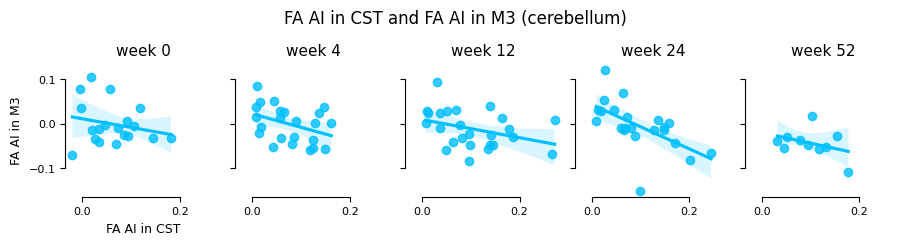

**Pearson R and p-value for FA in affected CST and GMV in M3L (cerebellum)** 

week 0: r = -0.22265589766428415, p-value = 0.3595505023894621
week 4: r = -0.3876849283443468, p-value = 0.06757516161678616
week 12: r = -0.3595375548579218, p-value = 0.07752594728206288
week 24: r = -0.5903021364885483, p-value = 0.0038264722949720854
week 52: r = -0.3664939492495609, p-value = 0.29757707977673686


In [19]:
fig, axs = plt.subplots(1, 5, figsize = (9,2), sharey = True, sharex = True, constrained_layout = True)
for i, week in enumerate(gl.weeks):
    cerebel_plot = cerebel[cerebel.Week == week]
    cst_plot = cst[(cst.Week == week)]
    cerebel_cst_plot = pd.merge(cst_plot, cerebel_plot, on = ['subj_id', 'Week'], suffixes = ('_cst', '_cerebel'))

    ax = axs[i]
    sns.regplot(x = 'asymmetry_index_cst', y = 'asymmetry_index_cerebel', data = cerebel_cst_plot, ax = ax, color = 'deepskyblue')

    ax.set_ylabel('')
    ax.set_xlabel('')

    ax.set_title(f'week {week}')

axs[0].set_ylabel("FA AI in M3")
axs[0].set_xlabel(f"FA AI in CST")
fig.suptitle(f"FA AI in CST and FA AI in M3 (cerebellum)", y = 1.15)
sns.despine(trim = True)
plt.show()


print("**Pearson R and p-value for FA in affected CST and GMV in M3L (cerebellum)** \n")
for week in gl.weeks:
    cerebel_plot = cerebel[cerebel.Week == week]
    cst_plot = cst[(cst.Week == week)]
    cerebel_cst_plot = pd.merge(cst_plot, cerebel_plot, on = ['subj_id', 'Week'], suffixes = ('_cst', '_cerebel'))


    r_stat, p_stat = stats.pearsonr(cerebel_cst_plot['asymmetry_index_cst'], cerebel_cst_plot['asymmetry_index_cerebel'])
    print(f'week {week}: r = {r_stat}, p-value = {p_stat}')

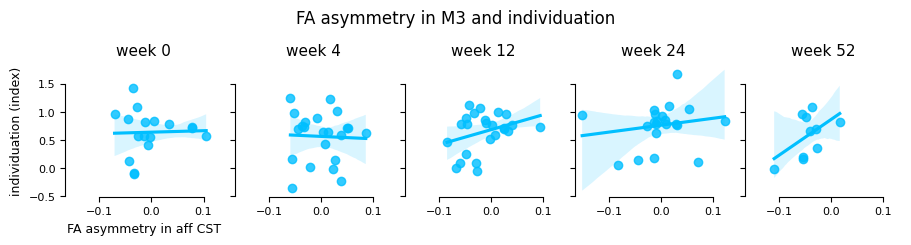

**Pearson R and p-value for FA asymmetry in M3 and individuation** 

week 0: r = 0.03239754186628536, p-value = 0.9017623904006854
week 4: r = -0.04034260453723486, p-value = 0.8585264676242075
week 12: r = 0.32490159844052324, p-value = 0.12136037139168113
week 24: r = 0.17583973023630556, p-value = 0.44580495896434946
week 52: r = 0.5232199465575254, p-value = 0.12067416856616774


In [22]:
fig, axs = plt.subplots(1, 5, figsize = (9,2), sharey = True, sharex = True, constrained_layout = True)
for i, week in enumerate(gl.weeks):
    behav_plot = behav[behav.Week == week]
    cerebel_plot = cerebel[(cerebel.Week == week)]
    behav_cerebel_plot = pd.merge(cerebel_plot, behav_plot, on = ['subj_id', 'Week'], suffixes = ('_cerebel', '_behav'))

    ax = axs[i]
    sns.regplot(x = 'asymmetry_index', y = 'indiv_norm', data = behav_cerebel_plot, ax = ax, color = 'deepskyblue')

    ax.set_ylabel('')
    ax.set_xlabel('')

    ax.set_title(f'week {week}')
    

axs[0].set_ylabel("individuation (index)")
axs[0].set_xlabel(f"FA asymmetry in aff CST")
fig.suptitle(f"FA asymmetry in M3 and individuation", y = 1.15)

sns.despine(trim = True)
plt.show()


print("**Pearson R and p-value for FA asymmetry in M3 and individuation** \n")
for week in gl.weeks:
    behav_plot = behav[behav.Week == week]
    cerebel_plot = cerebel[(cerebel.Week == week)]
    behav_cerebel_plot = pd.merge(cerebel_plot, behav_plot, on = ['subj_id', 'Week'], suffixes = ('_cerebel', '_behav'))

    r_stat, p_stat = stats.pearsonr(behav_cerebel_plot['asymmetry_index'], behav_cerebel_plot['indiv_norm'])
    print(f'week {week}: r = {r_stat}, p-value = {p_stat}')
